In [114]:
import csv
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from boruta import BorutaPy
from sklearn.svm import SVR
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

### Data Analysis

In [115]:
df = pd.read_csv('NASA_2022_2023.csv')
df

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,RH2M,PS,WS10M,WD10M
0,2022,1,1,0,0.0,12.07,81.81,97.93,2.09,247.17
1,2022,1,1,1,0.0,11.81,82.25,97.92,1.85,242.57
2,2022,1,1,2,0.0,11.60,82.56,97.90,1.72,243.90
3,2022,1,1,3,0.0,11.38,83.44,97.87,1.94,249.52
4,2022,1,1,4,0.0,11.10,85.06,97.89,2.30,256.67
...,...,...,...,...,...,...,...,...,...,...
17539,2024,1,1,19,0.0,14.56,75.81,98.59,4.58,332.61
17540,2024,1,1,20,0.0,14.26,79.94,98.62,4.65,335.93
17541,2024,1,1,21,0.0,14.50,80.25,98.64,4.62,342.36
17542,2024,1,1,22,0.0,14.24,81.56,98.64,4.61,348.96


In [116]:
df['All Sky Surface Shortwave Downward Irradiance'] = df['ALLSKY_SFC_SW_DWN']
df['Temperature at 2 Meters'] = df['T2M']
df['Relative Humidity at 2 Meters'] = df['RH2M']
df['Surface Pressure'] = df['PS']
df['Wind Speed at 10 Meters'] = df['WS10M']
df['Wind Direction at 10 Meters'] = df['WD10M']

df = df.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
df

,YEAR,MO,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2022,1,1,0,0.0,12.07,81.81,97.93,2.09,247.17
1,2022,1,1,1,0.0,11.81,82.25,97.92,1.85,242.57
2,2022,1,1,2,0.0,11.60,82.56,97.90,1.72,243.90
3,2022,1,1,3,0.0,11.38,83.44,97.87,1.94,249.52
4,2022,1,1,4,0.0,11.10,85.06,97.89,2.30,256.67
...,...,...,...,...,...,...,...,...,...,...
17539,2024,1,1,19,0.0,14.56,75.81,98.59,4.58,332.61
17540,2024,1,1,20,0.0,14.26,79.94,98.62,4.65,335.93
17541,2024,1,1,21,0.0,14.50,80.25,98.64,4.62,342.36
17542,2024,1,1,22,0.0,14.24,81.56,98.64,4.61,348.96


### Anova Feature Selection

Selected feature names: ['Temperature at 2 Meters', 'Relative Humidity at 2 Meters', 'Wind Speed at 10 Meters', 'Surface Pressure', 'DY']
the number of features:  5
Seelcted Features Scores:  [('Temperature at 2 Meters', 1.8047144994411417), ('Relative Humidity at 2 Meters', 1.7213714057350802), ('Wind Speed at 10 Meters', 1.7054314493374036), ('Surface Pressure', 1.0840455069470485), ('DY', 0.9975478153046548)]


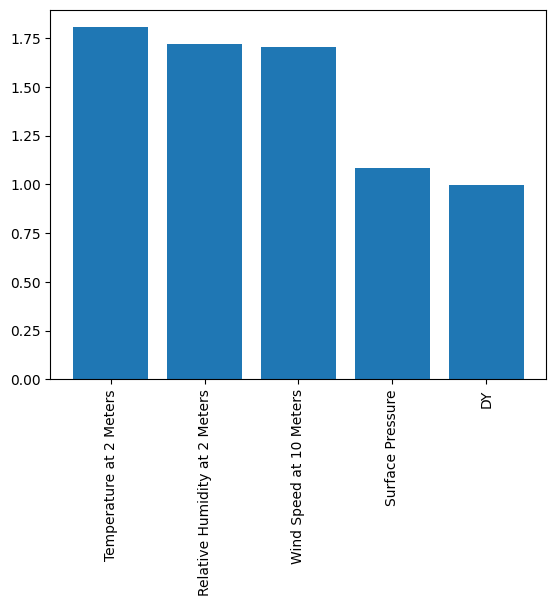

In [117]:
X = df.drop(columns=['All Sky Surface Shortwave Downward Irradiance', 'MO'])
y = df['All Sky Surface Shortwave Downward Irradiance']

selector = SelectKBest(f_classif, k=5)  # Select top 9 features
X_new = selector.fit_transform(X, y)
scores = selector.scores_
selected_feature_indices = selector.get_support(indices=True)
selected_features_with_scores = [(X.columns[i], scores[i]) for i in selected_feature_indices]
selected_features_with_scores.sort(key=lambda x: x[1], reverse=True)
sorted_selected_feature_names = [feature[0] for feature in selected_features_with_scores]
#selected_feature_names = X.columns[selected_feature_indices]
print("Selected feature names:", sorted_selected_feature_names)
print("the number of features: ", len(sorted_selected_feature_names))
print("Seelcted Features Scores: ", selected_features_with_scores)

plt.bar([feature[0] for feature in selected_features_with_scores], [feature[1] for feature in selected_features_with_scores])
plt.xticks(rotation=90)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Boruta Feature Selection

Boruta Ranking:  [2 1 1 1 1 1 1 1 1]
No. of significant features:  8


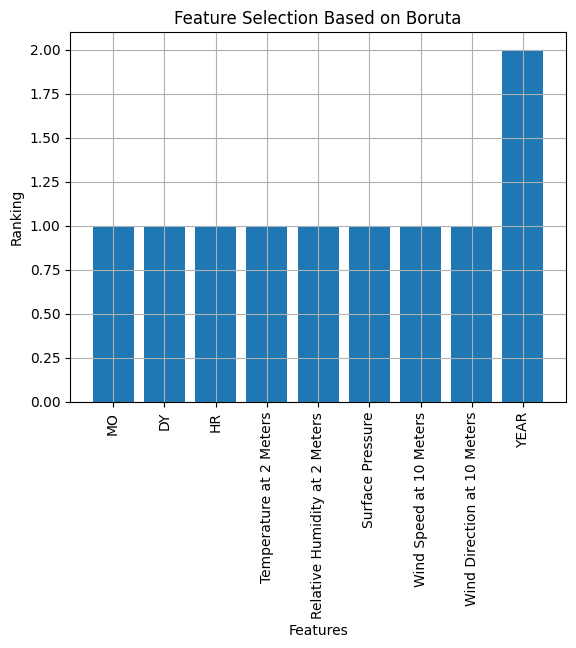

In [5]:
model = RandomForestRegressor()
boruta_selector = BorutaPy(model, n_estimators='auto', verbose=0, random_state=1, max_iter=100)
boruta_selector.fit(X.values, y.values)
print("Boruta Ranking: ", boruta_selector.ranking_)
print("No. of significant features: ", boruta_selector.n_features_)
selected_rf_features = pd.DataFrame({
    'Feature': list(X.columns),
    'Ranking': boruta_selector.ranking_
}).sort_values(by='Ranking')
# Selecting the columns with ranking 1
new_columns = selected_rf_features[selected_rf_features["Ranking"] == 1]['Feature']
X_new = X[new_columns]

plt.bar(selected_rf_features['Feature'], selected_rf_features['Ranking'])
plt.xticks(rotation=90)
plt.grid()
plt.title("Feature Selection Based on Boruta")
plt.xlabel("Features")
plt.ylabel("Ranking")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Linear Regression

In [118]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 45729.43698438767
RMSE: 213.84442238316078
R2: 0.5833151462479449
MAE: 174.8631181255519


### Gradient Boosting Regressor

In [119]:
gb = GradientBoostingRegressor()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 3627.827843283148
RMSE: 60.231452276058796
R2: 0.9669433735903601
MAE: 38.18101924729953


### Decision Tree Regressor

In [120]:
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 5581.730920632658
RMSE: 74.71098259715674
R2: 0.9491394846356583
MAE: 36.073074950128245


### Random Forest Regressor

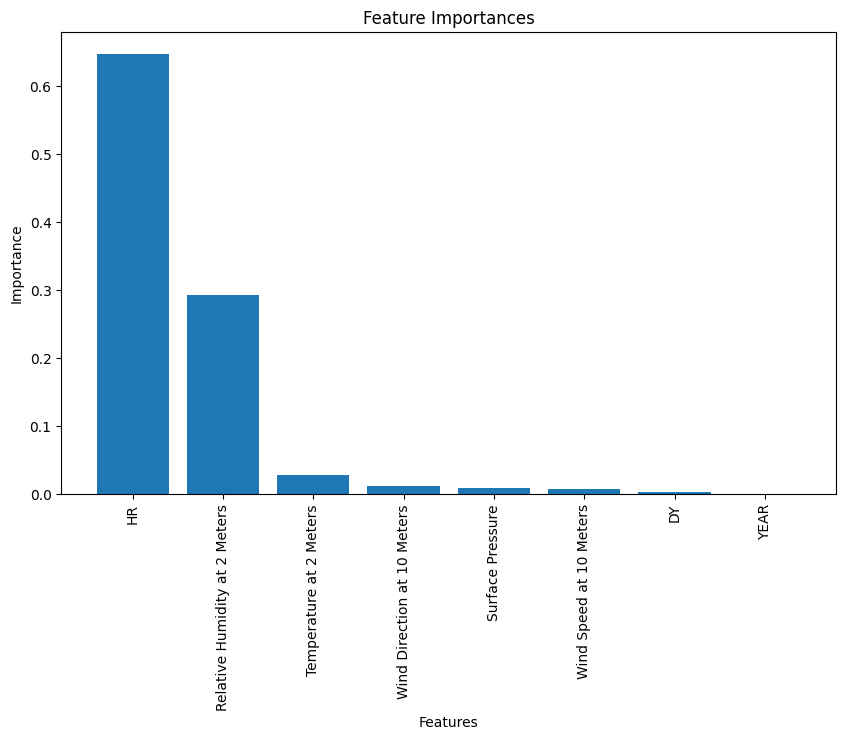

MSE: 2738.550752030255
RMSE: 52.331164252577594
R2: 0.975046431907922
MAE: 26.526205628384155


In [121]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=90)
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()
y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

In [122]:
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(10526, 8) (3509, 8) (3509, 8)


### CNN

In [123]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

X_train = np.expand_dims(X_train, axis=1)
X_test = np.expand_dims(X_test, axis=1)
X_val = np.expand_dims(X_val, axis=1)
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation='linear'),
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
329/329 [==============================] - 2s 5ms/step - loss: 102656.1719 - val_loss: 95406.6719
Epoch 2/1000
329/329 [==============================] - 2s 5ms/step - loss: 87368.1094 - val_loss: 79540.3906
Epoch 3/1000
329/329 [==============================] - 1s 4ms/step - loss: 74124.9844 - val_loss: 71108.5078
Epoch 4/1000
329/329 [==============================] - 1s 4ms/step - loss: 67703.6953 - val_loss: 65313.9531
Epoch 5/1000
329/329 [==============================] - 1s 4ms/step - loss: 64264.1836 - val_loss: 63104.5234
Epoch 6/1000
329/329 [==============================] - 1s 4ms/step - loss: 62066.0820 - val_loss: 61668.3047
Epoch 7/1000
329/329 [==============================] - 1s 4ms/step - loss: 60768.2812 - val_loss: 59904.4961
Epoch 8/1000
329/329 [==============================] - 1s 4ms/step - loss: 59483.1484 - val_loss: 58739.3750
Epoch 9/1000
329/329 [==============================] - 1s 4ms/step - loss: 58291.9844 - val_loss: 57902.8906
Epoch 10/

### LSTM

In [124]:
model_lstm = tf.keras.models.Sequential([
    tf.keras.layers.LSTM(32, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_lstm.compile(optimizer='adam', loss='mse')

model_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model_lstm.predict(X_test)
y_pred = np.squeeze(y_pred)
y_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
329/329 [==============================] - 4s 9ms/step - loss: 103666.6484 - val_loss: 95137.8672
Epoch 2/1000
329/329 [==============================] - 3s 8ms/step - loss: 82105.2891 - val_loss: 81712.6641
Epoch 3/1000
329/329 [==============================] - 3s 8ms/step - loss: 70465.4141 - val_loss: 64637.2930
Epoch 4/1000
329/329 [==============================] - 3s 8ms/step - loss: 63047.5703 - val_loss: 63129.9492
Epoch 5/1000
329/329 [==============================] - 3s 8ms/step - loss: 63116.1406 - val_loss: 60199.1719
Epoch 6/1000
329/329 [==============================] - 3s 8ms/step - loss: 58888.2383 - val_loss: 68073.4766
Epoch 7/1000
329/329 [==============================] - 3s 8ms/step - loss: 59060.8672 - val_loss: 56698.7031
Epoch 8/1000
329/329 [==============================] - 3s 8ms/step - loss: 56952.5820 - val_loss: 53300.2773
Epoch 9/1000
329/329 [==============================] - 3s 8ms/step - loss: 55302.0977 - val_loss: 53390.0547
Epoch 10/

### CNN LSTM

In [125]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

model_cnn_lstm = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Flatten()),
    tf.keras.layers.LSTM(32, activation='relu', return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_cnn_lstm.compile(optimizer='adam', loss='mse')

model_cnn_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model_cnn_lstm.predict(X_test)
y_pred = np.squeeze(y_pred)
y_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
329/329 [==============================] - 4s 10ms/step - loss: 116815.2344 - val_loss: 107712.3828
Epoch 2/1000
329/329 [==============================] - 3s 9ms/step - loss: 99713.6172 - val_loss: 90075.9609
Epoch 3/1000
329/329 [==============================] - 3s 9ms/step - loss: 77566.1953 - val_loss: 73112.9922
Epoch 4/1000
329/329 [==============================] - 3s 9ms/step - loss: 66497.5078 - val_loss: 64567.2500
Epoch 5/1000
329/329 [==============================] - 3s 10ms/step - loss: 62509.5469 - val_loss: 62454.4375
Epoch 6/1000
329/329 [==============================] - 3s 9ms/step - loss: 60079.6367 - val_loss: 60717.1641
Epoch 7/1000
329/329 [==============================] - 3s 9ms/step - loss: 57964.9922 - val_loss: 56930.4375
Epoch 8/1000
329/329 [==============================] - 3s 10ms/step - loss: 56791.6992 - val_loss: 57740.3281
Epoch 9/1000
329/329 [==============================] - 3s 9ms/step - loss: 55281.4258 - val_loss: 55079.5312
Epoch

### From 1/1/2024 to 1/2/2024 predictions

In [126]:
df_test = pd.read_csv('Test2_POWER_Point_Hourly_20240101_20240201_029d20N_032d62E_LST.csv')
df_test['All Sky Surface Shortwave Downward Irradiance'] = df_test['ALLSKY_SFC_SW_DWN']
df_test['Temperature at 2 Meters'] = df_test['T2M']
df_test['Relative Humidity at 2 Meters'] = df_test['RH2M']
df_test['Surface Pressure'] = df_test['PS']
df_test['Wind Speed at 10 Meters'] = df_test['WS10M']
df_test['Wind Direction at 10 Meters'] = df_test['WD10M']

df_test = df_test.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
df_test = df_test.drop(columns=['MO'])
df_test.head()

,YEAR,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2024,1,0,0.0,12.83,95.50,98.64,3.96,9.54
1,2024,1,1,0.0,12.87,96.31,98.63,3.78,9.40
2,2024,1,2,0.0,12.87,96.50,98.62,3.83,8.10
3,2024,1,3,0.0,12.83,97.19,98.61,4.01,8.51
4,2024,1,4,0.0,12.83,97.81,98.62,4.19,8.15


In [127]:
#list_prediction = []
#for i in range(len(df_test)):
#    prediction = rf.predict([df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance").iloc[i]])
#    list_prediction.append(prediction[0])

y_pred_lr = lr.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_gb = gb.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_dt = dt.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_rf = rf.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_cnn = model.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_lstm = model_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn_lstm = model_cnn_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn = np.squeeze(y_pred_cnn)
y_pred_lstm = np.squeeze(y_pred_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)

pred = [y_pred_lr, y_pred_gb, y_pred_dt, y_pred_rf, y_pred_cnn, y_pred_lstm, y_pred_cnn_lstm]
for i in range(len(pred)):
    r2 = r2_score(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    mse = mean_squared_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    print(f"R2 {i}: {r2}")
    print(f"MSE {i}: {mse}")
    print(f"RMSE {i}: {rmse}")
    print(f"MAE {i}: {mae}")


#df_test['Predicted All Sky Surface Shortwave Downward Irradiance'] = list_prediction
#df_test['Actuall All Sky Surface Shortwave Downward Irradiance'] = df_test['All Sky Surface Shortwave Downward Irradiance']
#df_test = df_test.drop(columns='All Sky Surface Shortwave Downward Irradiance')
#df_test.to_csv('DecisionTree_Predicted_POWER.csv', index=False)

 1/24 [>.............................] - ETA: 0s

24/24 [==============================] - 0s 4ms/step
R2 0: 0.571200923913767
MSE 0: 24389.69969386533
RMSE 0: 156.17201956133283
MAE 0: 126.7159259831757
R2 1: 0.9227539655749968
MSE 1: 4393.683865561619
RMSE 1: 66.2848690544201
MAE 1: 42.26708332884606
R2 2: 0.8920780693762845
MSE 2: 6138.5008156250005
RMSE 2: 78.34858528157991
MAE 2: 37.68072916666667
R2 3: 0.9474831677774888
MSE 3: 2987.109437060846
RMSE 3: 54.65445486930454
MAE 3: 25.910755078124996
R2 4: 0.463766424452565
MSE 4: 30500.475870287177
RMSE 4: 174.6438543730846
MAE 4: 130.4103766895846
R2 5: 0.3463384229344748
MSE 5: 37179.67331356948
RMSE 5: 192.82031353975515
MAE 5: 131.18602782845497
R2 6: 0.3751712168005259
MSE 6: 35539.690340316316
RMSE 6: 188.51973461766892
MAE 6: 132.2544303679466
